# Comparison with Sánchez Zaballa et al. (2025)

The two-zone results (Minuit, MCMC, UltraNest) next to the published one-zone model of
Sánchez Zaballa, Bottacini & Tramacere (2025).

In [ ]:
import os
os.makedirs('results/two_zone', exist_ok=True)
os.chdir('results/two_zone')            # everything this model reads and writes lives here

## Comparison table - published one-zone model
(Sanchez Zaballa, Bottacini & Tramacere 2025, arXiv:2505.13593, Table 2, eta=0.083) vs this work's two-zone model (Zone 1) Reads Minuit best-fit (TwoZone_7par_43pt.pkl) and ultranest posterior (ultranest_TwoZone_radio_reduced) for Zone 1.

In [29]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
from jetset.model_manager import FitModel

# 1. Published values (Sanchez Zaballa+2025, Table 2, eta=0.083)
published = {
    'R [cm]':            0.79e17,
    'R_H (R_diss) [cm]': 1.50e18,
    'B [G]':             6.56e-2,
    'theta [deg]':       3.00,
    'BulkFactor (Gamma)': 19.0,
    'delta (Doppler)':   19.0,
    'gmin':              1.00,
    'gamma_break':       0.94e3,
    'gmax':              2.00e4,
    'N [cm^-3]':         9.21e2,
    'p':                 1.45,
    'p_1':               3.58,
    'M_BH [Msun]':       1.10e9,
    'accr_eff (eta)':    0.083,
    'L_Disk [erg/s]':    1.41e46,
    'R_DT [cm]':         2.37e19,
    'T_DT [K]':          9.27e2,
    'R_BLR_in [cm]':     3.56e17,
    'R_BLR_out [cm]':    3.92e17,
}

# 2. This work: Minuit best-fit (7-param, 43 points)
model_minuit = FitModel.load_model('TwoZone_7par_43pt.pkl')
model_minuit.eval()

j1 = model_minuit.jet_leptonic

this_work_minuit = {
    'R [cm]':            j1.parameters.R.val,
    'R_H (R_diss) [cm]': j1.parameters.R_H.val,
    'B [G]':             j1.parameters.B.val,
    'theta [deg]':       j1.parameters.theta.val,
    'BulkFactor (Gamma)': j1.parameters.BulkFactor.val,
    'delta (Doppler)':   j1.get_beaming(),
    'gmin':              j1.parameters.gmin.val,
    'gamma_break':       j1.parameters.gamma_break.val,
    'gmax':              j1.parameters.gmax.val,
    'N [cm^-3]':         j1.parameters.N.val,
    'p':                 j1.parameters.p.val,
    'p_1':               j1.parameters.p_1.val,
    'M_BH [Msun]':       j1.parameters.M_BH.val,
    'accr_eff (eta)':    j1.parameters.accr_eff.val,
    'L_Disk [erg/s]':    j1.parameters.L_Disk.val,
    'R_DT [cm]':         j1.parameters.R_DT.val,
    'T_DT [K]':          j1.parameters.T_DT.val,
    'R_BLR_in [cm]':     j1.parameters.R_BLR_in.val,
    'R_BLR_out [cm]':    j1.parameters.R_BLR_out.val,
}

# 3. This work: ultranest posterior median + 1-sigma (7 free params)
#    Free: B, BulkFactor, N, gamma_break, R_H, accr_eff (zone1)
#          N (zone2, not relevant to this zone1 table)
#    Derived (R, delta, R_DT, R_BLR_in/out, L_Disk-dependent
#    quantities) recomputed at the median by re-evaluating
#    the model.
free_params_zone1 = ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']

samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                      skiprows=1)
median_vals = np.median(samples, axis=0)
p16 = np.percentile(samples, 16, axis=0)
p84 = np.percentile(samples, 84, axis=0)

# Apply zone1 median values (first 6 columns) to a fresh copy
model_un = FitModel.load_model('TwoZone_7par_43pt.pkl')
j1_un = model_un.jet_leptonic
for i, name in enumerate(free_params_zone1):
    j1_un.parameters.get_par_by_name(name).val = median_vals[i]
model_un.eval()

this_work_ultranest = {
    'R [cm]':            j1_un.parameters.R.val,
    'R_H (R_diss) [cm]': j1_un.parameters.R_H.val,
    'B [G]':             j1_un.parameters.B.val,
    'theta [deg]':       j1_un.parameters.theta.val,
    'BulkFactor (Gamma)': j1_un.parameters.BulkFactor.val,
    'delta (Doppler)':   j1_un.get_beaming(),
    'gmin':              j1_un.parameters.gmin.val,
    'gamma_break':       j1_un.parameters.gamma_break.val,
    'gmax':              j1_un.parameters.gmax.val,
    'N [cm^-3]':         j1_un.parameters.N.val,
    'p':                 j1_un.parameters.p.val,
    'p_1':               j1_un.parameters.p_1.val,
    'M_BH [Msun]':       j1_un.parameters.M_BH.val,
    'accr_eff (eta)':    j1_un.parameters.accr_eff.val,
    'L_Disk [erg/s]':    j1_un.parameters.L_Disk.val,
    'R_DT [cm]':         j1_un.parameters.R_DT.val,
    'T_DT [K]':          j1_un.parameters.T_DT.val,
    'R_BLR_in [cm]':     j1_un.parameters.R_BLR_in.val,
    'R_BLR_out [cm]':    j1_un.parameters.R_BLR_out.val,
}

# 1-sigma for the 6 free params (others are frozen, no uncertainty here)
sigma_lo = {}
sigma_hi = {}
for i, name in enumerate(free_params_zone1):
    key_map = {
        'B': 'B [G]', 'BulkFactor': 'BulkFactor (Gamma)', 'N': 'N [cm^-3]',
        'gamma_break': 'gamma_break', 'R_H': 'R_H (R_diss) [cm]',
        'accr_eff': 'accr_eff (eta)'
    }
    key = key_map[name]
    sigma_lo[key] = median_vals[i] - p16[i]
    sigma_hi[key] = p84[i] - median_vals[i]

# 4. Print comparison table
print(">>> Checkpoint 9.1: Comparison table")
print(f"{'Parameter':<22} {'Published':>14} {'This work (Minuit)':>20} "
      f"{'This work (ultranest)':>24}")
print("-" * 84)
for key in published:
    pub = published[key]
    mw = this_work_minuit[key]
    uw = this_work_ultranest[key]
    if key in sigma_lo:
        uw_str = f"{uw:.3e} (-{sigma_lo[key]:.2e}/+{sigma_hi[key]:.2e})"
    else:
        uw_str = f"{uw:.3e} (frozen)"
    print(f"{key:<22} {pub:>14.3e} {mw:>20.3e} {uw_str:>24}")

# 5. Save to file
with open('comparison_with_sanchez_zaballa_2025.txt', 'w') as f:
    f.write("Comparison: Sanchez Zaballa, Bottacini & Tramacere (2025, arXiv:2505.13593)\n")
    f.write("one-zone model (Table 2, eta=0.083) vs this work's two-zone model (Zone 1)\n")
    f.write("="*90 + "\n\n")
    f.write(f"{'Parameter':<22} {'Published':>14} {'This work (Minuit)':>20} "
            f"{'This work (ultranest)':>24}\n")
    f.write("-"*90 + "\n")
    for key in published:
        pub = published[key]
        mw = this_work_minuit[key]
        uw = this_work_ultranest[key]
        if key in sigma_lo:
            uw_str = f"{uw:.3e} (-{sigma_lo[key]:.2e}/+{sigma_hi[key]:.2e})"
        else:
            uw_str = f"{uw:.3e} (frozen)"
        f.write(f"{key:<22} {pub:>14.3e} {mw:>20.3e} {uw_str:>24}\n")

    f.write("\nNOTES:\n")
    f.write("- 'Published' = Sanchez Zaballa+2025 one-zone best-fit (Table 2, eta=0.083)\n")
    f.write("- 'This work' Zone 1 = compact zone (between BLR and DT), Sync+SSC+EC\n")
    f.write("- This work additionally includes a Zone 2 (extended, beyond DT,\n")
    f.write("  Sync+SSC only) which fits the radio data points not modeled\n")
    f.write("  in the published one-zone work, plus the NuSTAR hard X-ray points.\n")
    f.write("- Differences in B, BulkFactor, N, gamma_break, p, p_1 reflect the\n")
    f.write("  redistribution of the emission budget across two zones and the\n")
    f.write("  inclusion of additional (radio + NuSTAR) data.\n")
    f.write("- Central-engine quantities (M_BH, L_Disk, accr_eff, R_DT, T_DT,\n")
    f.write("  R_BLR_in/out) agree well between the two works, anchored by the\n")
    f.write("  same accretion-disk thermal bump in the optical/UV data.\n")

print("\n>>> PART 9 COMPLETE.")
print("    Saved: comparison_with_sanchez_zaballa_2025.txt")

===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
adding par: R_ext_Sw to  R_ext_Sw
adding par: accr_eff to  accr_eff
adding par: M_BH to  M_BH
adding par: tau_BLR to  tau_BLR
adding par: L_Disk to  L_D

## Plot the Part 9 comparison
Published (Sanchez Zaballa+2025) vs This work (Minuit/ultranest) Two panels: 1. Jet/electron-distribution parameters (B, Gamma, N, gamma_break, p, p_1, R, R_H) - log scale, normalized to published value for visual comparison 2. Central-engine parameters (M_BH, L_Disk, accr_eff, R_DT, T_DT, R_BLR_in/out) - log scale, normalized

===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
adding par: R_ext_Sw to  R_ext_Sw
adding par: accr_eff to  accr_eff
adding par: M_BH to  M_BH
adding par: tau_BLR to  tau_BLR
adding par: L_Disk to  L_D

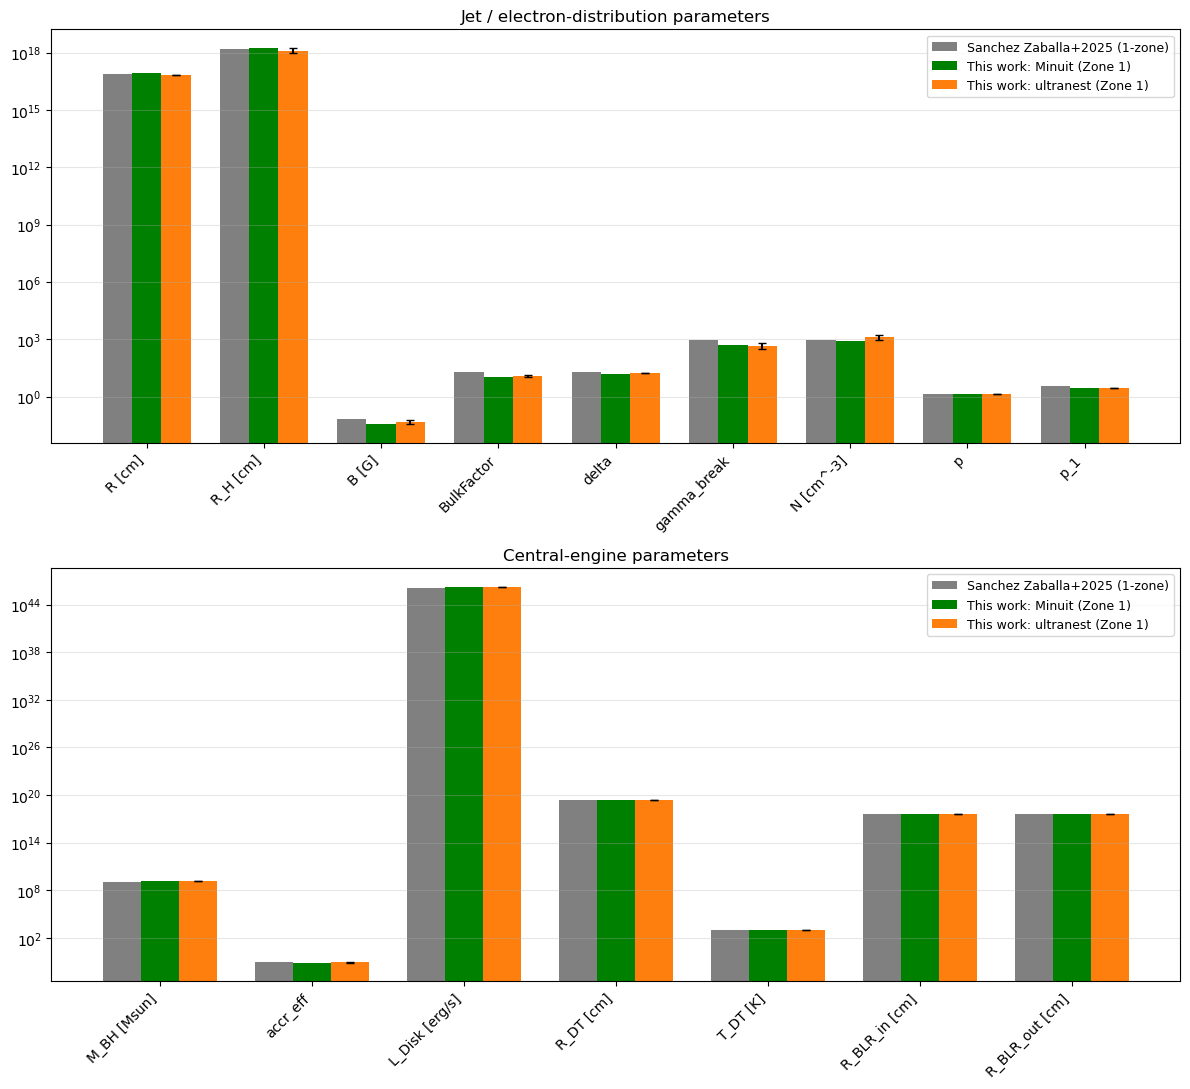

>>> Checkpoint 11.2: Bar plot saved -> comparison_with_published_barplot.png


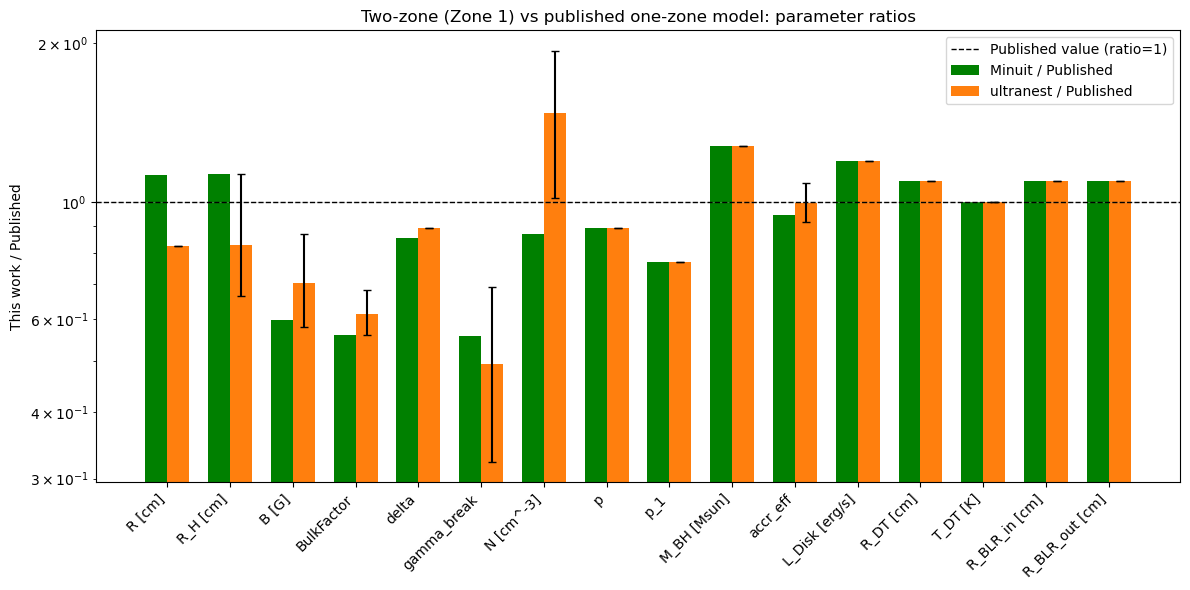

>>> Checkpoint 11.3: Ratio plot saved -> comparison_with_published_ratio.png

>>> PART 11 COMPLETE.
    Saved: comparison_with_published_barplot.png, comparison_with_published_ratio.png


In [30]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.model_manager import FitModel

# 1. Published values (Sanchez Zaballa+2025, Table 2, eta=0.083)
published = {
    'R [cm]':            0.79e17,
    'R_H [cm]':          1.50e18,
    'B [G]':             6.56e-2,
    'BulkFactor':        19.0,
    'delta':             19.0,
    'gamma_break':       0.94e3,
    'N [cm^-3]':         9.21e2,
    'p':                 1.45,
    'p_1':               3.58,
    'M_BH [Msun]':       1.10e9,
    'accr_eff':          0.083,
    'L_Disk [erg/s]':    1.41e46,
    'R_DT [cm]':         2.37e19,
    'T_DT [K]':          9.27e2,
    'R_BLR_in [cm]':     3.56e17,
    'R_BLR_out [cm]':    3.92e17,
}

# 2. This work: Minuit + ultranest (Zone 1)
model_minuit = FitModel.load_model('TwoZone_7par_43pt.pkl')
model_minuit.eval()
j1 = model_minuit.jet_leptonic

this_work_minuit = {
    'R [cm]':            j1.parameters.R.val,
    'R_H [cm]':          j1.parameters.R_H.val,
    'B [G]':             j1.parameters.B.val,
    'BulkFactor':        j1.parameters.BulkFactor.val,
    'delta':             j1.get_beaming(),
    'gamma_break':       j1.parameters.gamma_break.val,
    'N [cm^-3]':         j1.parameters.N.val,
    'p':                 j1.parameters.p.val,
    'p_1':               j1.parameters.p_1.val,
    'M_BH [Msun]':       j1.parameters.M_BH.val,
    'accr_eff':          j1.parameters.accr_eff.val,
    'L_Disk [erg/s]':    j1.parameters.L_Disk.val,
    'R_DT [cm]':         j1.parameters.R_DT.val,
    'T_DT [K]':          j1.parameters.T_DT.val,
    'R_BLR_in [cm]':     j1.parameters.R_BLR_in.val,
    'R_BLR_out [cm]':    j1.parameters.R_BLR_out.val,
}

free_params_zone1 = ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']
key_map = {
    'B': 'B [G]', 'BulkFactor': 'BulkFactor', 'N': 'N [cm^-3]',
    'gamma_break': 'gamma_break', 'R_H': 'R_H [cm]', 'accr_eff': 'accr_eff'
}

samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                      skiprows=1)
median_vals = np.median(samples, axis=0)
p16 = np.percentile(samples, 16, axis=0)
p84 = np.percentile(samples, 84, axis=0)

model_un = FitModel.load_model('TwoZone_7par_43pt.pkl')
j1_un = model_un.jet_leptonic
for i, name in enumerate(free_params_zone1):
    j1_un.parameters.get_par_by_name(name).val = median_vals[i]
model_un.eval()

this_work_ultranest = {
    'R [cm]':            j1_un.parameters.R.val,
    'R_H [cm]':          j1_un.parameters.R_H.val,
    'B [G]':             j1_un.parameters.B.val,
    'BulkFactor':        j1_un.parameters.BulkFactor.val,
    'delta':             j1_un.get_beaming(),
    'gamma_break':       j1_un.parameters.gamma_break.val,
    'N [cm^-3]':         j1_un.parameters.N.val,
    'p':                 j1_un.parameters.p.val,
    'p_1':               j1_un.parameters.p_1.val,
    'M_BH [Msun]':       j1_un.parameters.M_BH.val,
    'accr_eff':          j1_un.parameters.accr_eff.val,
    'L_Disk [erg/s]':    j1_un.parameters.L_Disk.val,
    'R_DT [cm]':         j1_un.parameters.R_DT.val,
    'T_DT [K]':          j1_un.parameters.T_DT.val,
    'R_BLR_in [cm]':     j1_un.parameters.R_BLR_in.val,
    'R_BLR_out [cm]':    j1_un.parameters.R_BLR_out.val,
}

# 1-sigma errors (only for the 6 free zone1 params)
sigma_lo = {}
sigma_hi = {}
for i, name in enumerate(free_params_zone1):
    key = key_map[name]
    sigma_lo[key] = median_vals[i] - p16[i]
    sigma_hi[key] = p84[i] - median_vals[i]

print(">>> Checkpoint 11.1: Values loaded for plotting")

# 3. Split into two groups for plotting
jet_params = ['R [cm]', 'R_H [cm]', 'B [G]', 'BulkFactor', 'delta',
               'gamma_break', 'N [cm^-3]', 'p', 'p_1']
engine_params = ['M_BH [Msun]', 'accr_eff', 'L_Disk [erg/s]', 'R_DT [cm]',
                  'T_DT [K]', 'R_BLR_in [cm]', 'R_BLR_out [cm]']

def make_panel(ax, keys, title):
    x = np.arange(len(keys))
    width = 0.25

    pub_vals = [published[k] for k in keys]
    minuit_vals = [this_work_minuit[k] for k in keys]
    un_vals = [this_work_ultranest[k] for k in keys]
    un_err_lo = [sigma_lo.get(k, 0) for k in keys]
    un_err_hi = [sigma_hi.get(k, 0) for k in keys]

    ax.bar(x - width, pub_vals, width, label='Sanchez Zaballa+2025 (1-zone)',
           color='gray')
    ax.bar(x, minuit_vals, width, label='This work: Minuit (Zone 1)',
           color='green')
    ax.bar(x + width, un_vals, width, yerr=[un_err_lo, un_err_hi],
           label='This work: ultranest (Zone 1)', color='C1', capsize=3)

    ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels(keys, rotation=45, ha='right')
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

fig, axes = plt.subplots(2, 1, figsize=(12, 11))
make_panel(axes[0], jet_params, 'Jet / electron-distribution parameters')
make_panel(axes[1], engine_params, 'Central-engine parameters')

plt.tight_layout()
plt.savefig('comparison_with_published_barplot.png', dpi=150, bbox_inches='tight')
plt.show()

print(">>> Checkpoint 11.2: Bar plot saved -> comparison_with_published_barplot.png")

# 4. Ratio plot (this work / published) - easier to read at a glance
all_keys = jet_params + engine_params
ratio_minuit = [this_work_minuit[k] / published[k] for k in all_keys]
ratio_un = [this_work_ultranest[k] / published[k] for k in all_keys]
ratio_un_err_lo = [sigma_lo.get(k, 0) / published[k] for k in all_keys]
ratio_un_err_hi = [sigma_hi.get(k, 0) / published[k] for k in all_keys]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(all_keys))
width = 0.35

ax.bar(x - width/2, ratio_minuit, width, label='Minuit / Published', color='green')
ax.bar(x + width/2, ratio_un, width, yerr=[ratio_un_err_lo, ratio_un_err_hi],
       label='ultranest / Published', color='C1', capsize=3)

ax.axhline(1.0, color='k', ls='--', lw=1, label='Published value (ratio=1)')
ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels(all_keys, rotation=45, ha='right')
ax.set_ylabel('This work / Published')
ax.set_title('Two-zone (Zone 1) vs published one-zone model: parameter ratios')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('comparison_with_published_ratio.png', dpi=150, bbox_inches='tight')
plt.show()

print(">>> Checkpoint 11.3: Ratio plot saved -> comparison_with_published_ratio.png")

print("\n>>> PART 11 COMPLETE.")
print("    Saved: comparison_with_published_barplot.png, "
      "comparison_with_published_ratio.png")

## All SEDs together - this work (Minuit/MCMC/ultranest
two-zone) + reconstructed Sanchez Zaballa+2025 (2025) one-zone model The published one-zone jet is built from Table 2 (eta=0.083) parameters and evaluated with jetset, since we don't have their raw SED curve -- only their best-fit parameters.

---> excluding  data_set/s ['-1']
filter -1 43
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=43
>>> Checkpoint 12.1: Data loaded (43 points)
===> setting C threads to 8
adding par: z_cosm to  z_cosm
>>> Checkpoint 12.2: Reconstructed Sanchez Zaballa+2025 one-zone model
    beaming (delta) = 19.107 (published delta = 19.0)
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
addin

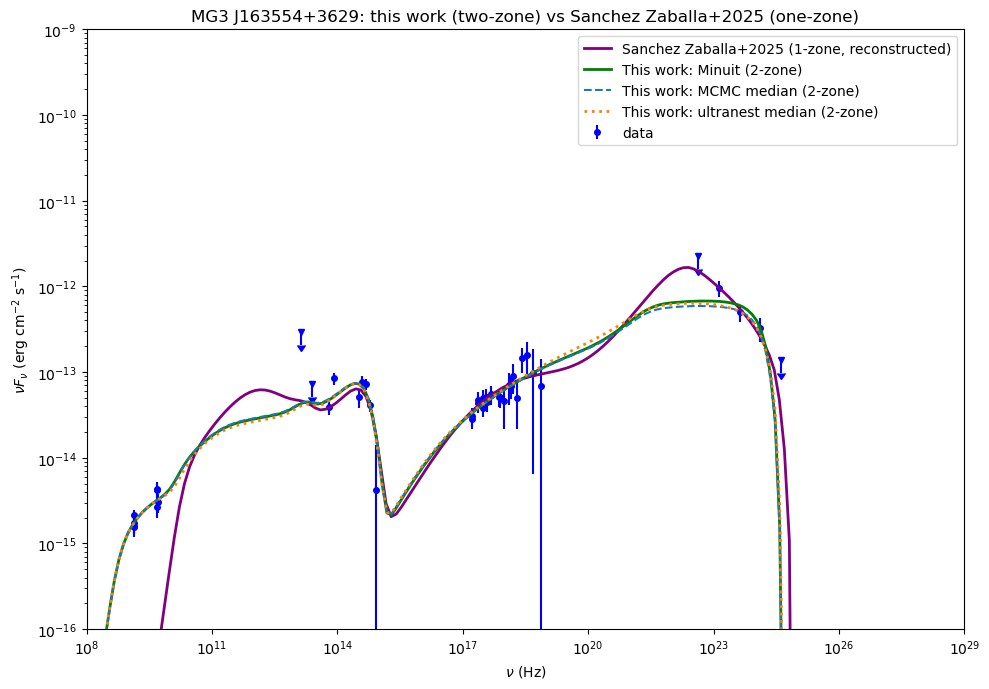


>>> PART 12 COMPLETE.
    Saved: all_seds_with_published.png
    NOTE: the published curve is RECONSTRUCTED from Table 2
    parameters using jetset, not their original plotted curve --
    minor differences from their Figure 1 may exist due to
    different EBL/SED-grid settings or rounding in Table 2.


In [33]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData
from jetset.jet_model import Jet
from jetset.model_manager import FitModel
from jetset.template_2Dmodel import EBLAbsorptionTemplate

# 1. Load data (43 points, top-2 Fermi excluded)
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]
d = d[~np.isin(d[:, 0], [1.324e25, 7.646e25])]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data_43 = ObsData(data_table=data_obj)
sed_data_43.filter_data_set('-1', exclude=True)
sed_data_43.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data_43.table['nu_data'], freq, rtol=0.05)
    sed_data_43.table['UL'][mask] = True

nu_obs   = np.array(sed_data_43.table['nu_data'])
flux_obs = np.array(sed_data_43.table['nuFnu_data'])
flux_err = np.array(sed_data_43.table['dnuFnu_data'])
is_ul    = np.array(sed_data_43.table['UL'], dtype=bool)

print(">>> Checkpoint 12.1: Data loaded (43 points)")

# 2. Reconstruct Sanchez Zaballa+2025 one-zone model
#    (Table 2, eta=0.083)
jose_jet = Jet(
    name='jose_onezone',
    electron_distribution='bkn',
    electron_distribution_log_values=False,
    beaming_expr='bulk_theta'
)

jose_jet.add_EC_component(EC_components_list=['EC_DT', 'EC_BLR', 'EC_Disk'],
                           disk_type='MultiBB')

jose_jet.set_par('z_cosm', val=3.647763)
jose_jet.set_par('theta', val=3.00)
jose_jet.set_par('BulkFactor', val=19.0)
jose_jet.set_par('R', val=0.79e17)
jose_jet.set_par('B', val=6.56e-2)

jose_jet.set_par('gmin', val=1.00)
jose_jet.set_par('gamma_break', val=0.94e3)
jose_jet.set_par('gmax', val=2.00e4)
jose_jet.set_par('N', val=9.21e2)
jose_jet.set_par('p', val=1.45)
jose_jet.set_par('p_1', val=3.58)

jose_jet.set_par('M_BH', val=1.10e9)
jose_jet.set_par('accr_eff', val=0.083)
jose_jet.set_par('L_Disk', val=1.41e46)
jose_jet.set_par('T_DT', val=9.27e2)
jose_jet.set_par('tau_DT', val=0.10)
jose_jet.set_par('tau_BLR', val=0.10)

# R_inner_Sw / R_ext_Sw -> Rin=9.27 RS, Rout=8.41e2 RS
jose_jet.set_par('R_inner_Sw', val=9.27)
jose_jet.set_par('R_ext_Sw', val=8.41e2)

# R_H = R_diss = 1.50e18 cm
jose_jet.set_par('R_H', val=1.50e18)
jose_jet.eval()

# add_EC_component does not automatically establish the
# R_DT(L_Disk) dependency for a standalone jet (unlike
# ObsConstrain.constrain_SSC_EC_model, which does). Set R_DT
# explicitly to the published value.
jose_jet.parameters.R_DT.val = 2.37e19
jose_jet.parameters.R_BLR_in.val = 3.56e17
jose_jet.parameters.R_BLR_out.val = 3.92e17
jose_jet.eval()
jose_model = FitModel(jet=jose_jet, name='Jose_OneZone')
ebl = EBLAbsorptionTemplate.from_name('Franceschini_2008')
jose_model.add_component(ebl)
jose_model.link_par(par_name='z_cosm', from_model='Franceschini_2008',
                     to_model='jose_onezone')
jose_model.composite_expr = 'jose_onezone * Franceschini_2008'

jose_model.eval()

print(">>> Checkpoint 12.2: Reconstructed Sanchez Zaballa+2025 one-zone model")
print(f"    beaming (delta) = {jose_jet.get_beaming():.3f} "
      f"(published delta = 19.0)")

nu_jose = np.array(jose_model.SED.nu)
flux_jose = np.array(jose_model.SED.nuFnu)

# 3. Load this work's models: Minuit, MCMC median, ultranest median
free_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']] +
    [('jet_extended', n) for n in ['N']]
)

model_minuit = FitModel.load_model('TwoZone_7par_43pt.pkl')
model_minuit.eval()
nu_minuit = np.array(model_minuit.SED.nu)
flux_minuit = np.array(model_minuit.SED.nuFnu)

import dill
with open('mcmc_7par_43pt.pkl', 'rb') as f:
    mcmc = dill.load(f)
mcmc_samples = np.asarray(mcmc.samples)
mcmc_median = np.median(mcmc_samples, axis=0)

un_samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                          skiprows=1)
un_median = np.median(un_samples, axis=0)

def eval_at(params):
    m = FitModel.load_model('TwoZone_7par_43pt.pkl')
    for (jet, name), val in zip(free_params, params):
        getattr(m, jet).set_par(name, val=val)
    m.eval()
    return np.array(m.SED.nu), np.array(m.SED.nuFnu)

nu_mcmc, flux_mcmc = eval_at(mcmc_median)
nu_un, flux_un = eval_at(un_median)

print(">>> Checkpoint 12.3: This work's models (Minuit, MCMC, ultranest) loaded")

# 4. Plot everything together
fig, ax = plt.subplots(figsize=(10, 7))

good_jose = flux_jose > 0
good_minuit = flux_minuit > 0
good_mcmc = flux_mcmc > 0
good_un = flux_un > 0

ax.plot(nu_jose[good_jose], flux_jose[good_jose], '-', color='purple',
        lw=2, label='Sanchez Zaballa+2025 (1-zone, reconstructed)', zorder=2)

ax.plot(nu_minuit[good_minuit], flux_minuit[good_minuit], '-', color='green',
        lw=2, label='This work: Minuit (2-zone)', zorder=3)
ax.plot(nu_mcmc[good_mcmc], flux_mcmc[good_mcmc], '--', color='C0',
        lw=1.5, label='This work: MCMC median (2-zone)', zorder=3)
ax.plot(nu_un[good_un], flux_un[good_un], ':', color='C1',
        lw=2, label='This work: ultranest median (2-zone)', zorder=3)

ax.errorbar(nu_obs[~is_ul], flux_obs[~is_ul], yerr=flux_err[~is_ul], fmt='o',
             color='blue', ms=4, label='data', zorder=1)
ax.errorbar(nu_obs[is_ul], flux_obs[is_ul], yerr=flux_obs[is_ul]*0.3, fmt='v',
             color='blue', ms=4, uplims=True, zorder=1)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-16, 1e-9)
ax.set_xlim(1e8, 1e29)
ax.set_xlabel(r'$\nu$ (Hz)')
ax.set_ylabel(r'$\nu F_\nu$ (erg cm$^{-2}$ s$^{-1}$)')
ax.legend(fontsize=10, loc='upper right')
ax.set_title('MG3 J163554+3629: this work (two-zone) vs '
              'Sanchez Zaballa+2025 (one-zone)')

plt.tight_layout()
plt.savefig('all_seds_with_published.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n>>> PART 12 COMPLETE.")
print("    Saved: all_seds_with_published.png")
print("    NOTE: the published curve is RECONSTRUCTED from Table 2")
print("    parameters using jetset, not their original plotted curve --")
print("    minor differences from their Figure 1 may exist due to")
print("    different EBL/SED-grid settings or rounding in Table 2.")

## Simple parameter comparison table (plotted)
Published (Sanchez Zaballa+2025, Table 2, eta=0.083) vs This work: Minuit and ultranest (Zone 1, two-zone model)

===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
adding par: R_ext_Sw to  R_ext_Sw
adding par: accr_eff to  accr_eff
adding par: M_BH to  M_BH
adding par: tau_BLR to  tau_BLR
adding par: L_Disk to  L_D

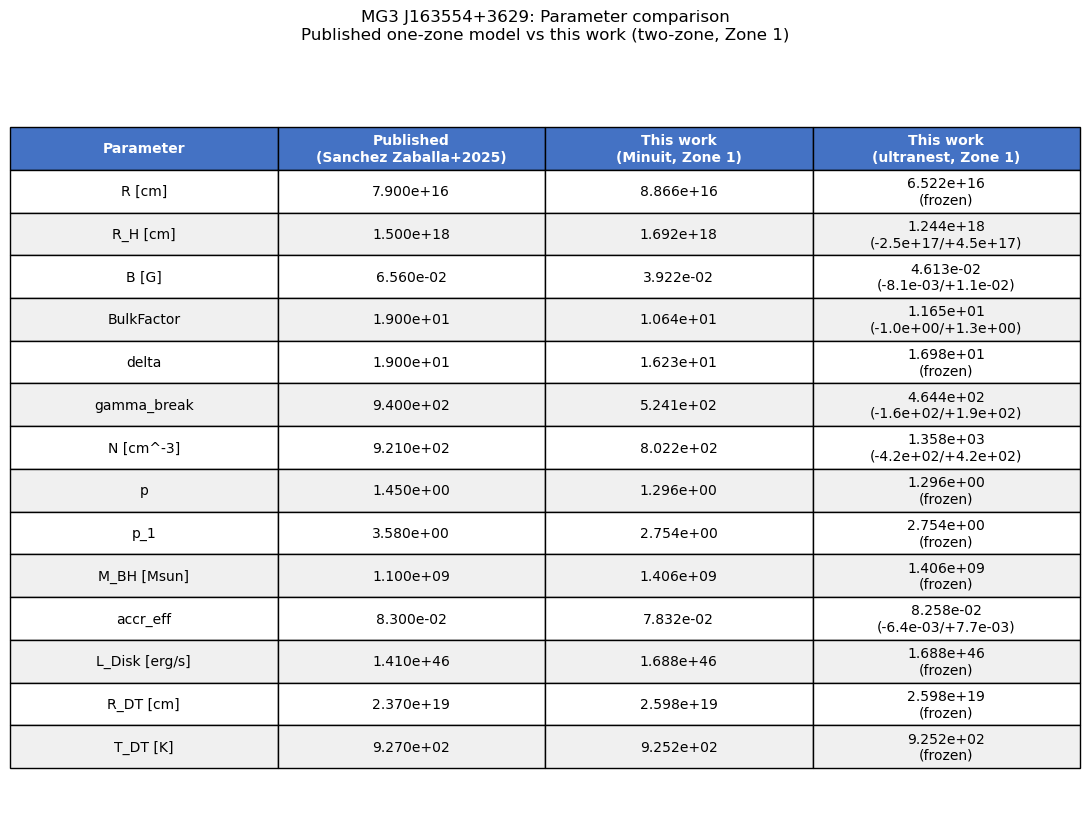

>>> PART 13 COMPLETE.
    Saved: parameter_comparison_table.png


In [34]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.model_manager import FitModel

# 1. Published values
published = {
    'R [cm]':            0.79e17,
    'R_H [cm]':          1.50e18,
    'B [G]':             6.56e-2,
    'BulkFactor':        19.0,
    'delta':             19.0,
    'gamma_break':       0.94e3,
    'N [cm^-3]':         9.21e2,
    'p':                 1.45,
    'p_1':               3.58,
    'M_BH [Msun]':       1.10e9,
    'accr_eff':          0.083,
    'L_Disk [erg/s]':    1.41e46,
    'R_DT [cm]':         2.37e19,
    'T_DT [K]':          9.27e2,
}

# 2. This work: Minuit
model_minuit = FitModel.load_model('TwoZone_7par_43pt.pkl')
model_minuit.eval()
j1 = model_minuit.jet_leptonic

this_work_minuit = {
    'R [cm]':            j1.parameters.R.val,
    'R_H [cm]':          j1.parameters.R_H.val,
    'B [G]':             j1.parameters.B.val,
    'BulkFactor':        j1.parameters.BulkFactor.val,
    'delta':             j1.get_beaming(),
    'gamma_break':       j1.parameters.gamma_break.val,
    'N [cm^-3]':         j1.parameters.N.val,
    'p':                 j1.parameters.p.val,
    'p_1':               j1.parameters.p_1.val,
    'M_BH [Msun]':       j1.parameters.M_BH.val,
    'accr_eff':          j1.parameters.accr_eff.val,
    'L_Disk [erg/s]':    j1.parameters.L_Disk.val,
    'R_DT [cm]':         j1.parameters.R_DT.val,
    'T_DT [K]':          j1.parameters.T_DT.val,
}

# 3. This work: ultranest median +/- 1sigma (free params only)
free_params_zone1 = ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']
key_map = {
    'B': 'B [G]', 'BulkFactor': 'BulkFactor', 'N': 'N [cm^-3]',
    'gamma_break': 'gamma_break', 'R_H': 'R_H [cm]', 'accr_eff': 'accr_eff'
}

samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                      skiprows=1)
median_vals = np.median(samples, axis=0)
p16 = np.percentile(samples, 16, axis=0)
p84 = np.percentile(samples, 84, axis=0)

model_un = FitModel.load_model('TwoZone_7par_43pt.pkl')
j1_un = model_un.jet_leptonic
for i, name in enumerate(free_params_zone1):
    j1_un.parameters.get_par_by_name(name).val = median_vals[i]
model_un.eval()

this_work_ultranest = {
    'R [cm]':            j1_un.parameters.R.val,
    'R_H [cm]':          j1_un.parameters.R_H.val,
    'B [G]':             j1_un.parameters.B.val,
    'BulkFactor':        j1_un.parameters.BulkFactor.val,
    'delta':             j1_un.get_beaming(),
    'gamma_break':       j1_un.parameters.gamma_break.val,
    'N [cm^-3]':         j1_un.parameters.N.val,
    'p':                 j1_un.parameters.p.val,
    'p_1':               j1_un.parameters.p_1.val,
    'M_BH [Msun]':       j1_un.parameters.M_BH.val,
    'accr_eff':          j1_un.parameters.accr_eff.val,
    'L_Disk [erg/s]':    j1_un.parameters.L_Disk.val,
    'R_DT [cm]':         j1_un.parameters.R_DT.val,
    'T_DT [K]':          j1_un.parameters.T_DT.val,
}

sigma_lo = {}
sigma_hi = {}
for i, name in enumerate(free_params_zone1):
    key = key_map[name]
    sigma_lo[key] = median_vals[i] - p16[i]
    sigma_hi[key] = p84[i] - median_vals[i]

# 4. Build table rows
def fmt(val):
    return f"{val:.3e}"

def fmt_un(key, val):
    if key in sigma_lo:
        return f"{val:.3e}\n(-{sigma_lo[key]:.1e}/+{sigma_hi[key]:.1e})"
    return f"{val:.3e}\n(frozen)"

rows = []
for key in published:
    rows.append([
        key,
        fmt(published[key]),
        fmt(this_work_minuit[key]),
        fmt_un(key, this_work_ultranest[key]),
    ])

col_labels = ['Parameter', 'Published\n(Sanchez Zaballa+2025)',
               'This work\n(Minuit, Zone 1)', 'This work\n(ultranest, Zone 1)']

# 5. Plot as a matplotlib table
fig, ax = plt.subplots(figsize=(11, 0.5 * len(rows) + 1.5))
ax.axis('off')

table = ax.table(
    cellText=rows,
    colLabels=col_labels,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2.2)

# Style header
for j in range(len(col_labels)):
    cell = table[0, j]
    cell.set_facecolor('#4472C4')
    cell.set_text_props(color='white', weight='bold')

# Alternate row shading
for i in range(1, len(rows) + 1):
    color = '#f0f0f0' if i % 2 == 0 else 'white'
    for j in range(len(col_labels)):
        table[i, j].set_facecolor(color)

ax.set_title('MG3 J163554+3629: Parameter comparison\n'
              'Published one-zone model vs this work (two-zone, Zone 1)',
              fontsize=12, pad=20)

plt.tight_layout()
plt.savefig('parameter_comparison_table.png', dpi=150, bbox_inches='tight')
plt.show()

print(">>> PART 13 COMPLETE.")
print("    Saved: parameter_comparison_table.png")